# 03 · Predicting new patients + robustness tests (Min16 robust pipeline)

Run `01` and `02` first. This notebook:

1. Defines `predict_new(df)`, the function a UI or web tool should call. It **refuses**
   to score a visit with fewer than 16 of the 30 clinical items answered, because the
   model was never trained or validated on such input.
2. Scores a **dummy CSV** (`dummy_patients.csv`, written here) of typical, borderline,
   random and sparse cases.
3. Runs a **blank-injection robustness test** on real test patients: extra blanks are
   added while keeping ≥ 16 answered. The old pipeline called 100 % of healthy
   test patients PD under this test. A sound model's predictions should barely move.

Input CSV format = the same columns as `Train/Sparse_Matrix_Min50_Train.csv`
(`PATNO`, `Age`, `Sex` 1 = male / 2 = female, and the clinical columns). `APPRDX` and `EVENT_ID`
are optional. Extra columns are ignored, and missing model columns are treated as blank.

In [ ]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import load

warnings.filterwarnings("ignore")
BASE_DIR = os.getcwd()   # run from the repository root
OUT_DIR  = BASE_DIR
sys.path.insert(0, OUT_DIR)
from min16_lib import predict_pipeline

ANALYSIS = "primary"            # or "sensitivity_original_cohort"
B        = load(os.path.join(OUT_DIR, "saved_models", ANALYSIS, "pipeline.joblib"))
CFG      = B["config"]
CLIN30   = CFG["clinical_columns"]
FEATURES = B["features"]
THR      = B["threshold"]
MIN_ANS  = CFG["min_answered"]
print(f"Model: {ANALYSIS} | {len(FEATURES)} features | threshold {THR:.3f} | "
      f"requires >= {MIN_ANS}/30 answered")

Model: primary | 30 features | threshold 0.611 | requires >= 16/30 answered


## 1. `predict_new`: the function a UI should call

In [ ]:
def predict_new(df, per="visit"):
    """
    Score new data.

    per = "visit"   -> every row is scored on its own (what a single-entry UI does)
    per = "patient" -> rows are averaged per PATNO (all eligible visits of a patient)

    Rows with fewer than MIN_ANS of the 30 clinical items answered are NOT scored
    (status = "insufficient data"), because the model was never validated on them.
    """
    d = df.copy().reset_index(drop=True)
    for c in CLIN30:
        if c not in d.columns:
            d[c] = np.nan
    d[CLIN30] = d[CLIN30].apply(pd.to_numeric, errors="coerce")
    d["n_answered"] = d[CLIN30].notna().sum(axis=1)
    d["n_model_features"] = d[FEATURES].notna().sum(axis=1)
    ok = d["n_answered"] >= MIN_ANS

    X = d[FEATURES].copy()
    X["age"] = pd.to_numeric(d["Age"], errors="coerce")
    X["sex"] = d["Sex"].map({1: 0, 2: 1}).astype(float)

    out = d[[c for c in ["PATNO", "EVENT_ID", "APPRDX"] if c in d]].copy()
    out["n_answered"] = d["n_answered"]
    out["status"] = np.where(ok, "scored", f"insufficient data (<{MIN_ANS}/30 answered)")
    for c in ["M1", "M2", "M3", "P_PD"]:
        out[c] = np.nan
    if ok.any():
        units = d.loc[ok, "PATNO"].values if per == "patient" else np.where(ok)[0]
        pr = predict_pipeline(B, X[ok], units)
        if per == "patient":
            res = pr.rename(columns={"Final": "P_PD"})[["M1", "M2", "M3", "P_PD"]]
            base = out.drop(columns=["M1", "M2", "M3", "P_PD"]).groupby("PATNO").agg(
                n_visits_scored=("status", lambda s: (s == "scored").sum()),
                **({"APPRDX": ("APPRDX", "first")} if "APPRDX" in out else {}))
            out = base.join(res, how="left").reset_index()
            out["status"] = np.where(out["P_PD"].notna(), "scored",
                                     f"insufficient data (<{MIN_ANS}/30 answered)")
        else:
            out.loc[ok, ["M1", "M2", "M3", "P_PD"]] = pr[["M1", "M2", "M3", "Final"]].values
    out["prediction"] = np.where(out["P_PD"].isna(), "-",
                                 np.where(out["P_PD"] >= THR, "PD", "Healthy"))
    return out

## 2. Dummy patients
Values are drawn from the ranges seen in the training CSV. Cases:

* **A/B**: typical healthy / typical PD (class medians), complete
* **C**: midpoint between the classes
* **D/E**: healthy / PD medians with only 16 items answered (just eligible)
* **F**: only 10 items answered, so it must be refused
* **G**: age and sex only, so it must be refused (the old model said 98 % PD here)
* **HC01–HC20 / PD01–PD20**: realistic synthetic patients. Each item is drawn
  independently from the real values of that class in training, with 16–30 items answered.
  Expected: most HC-sampled are called Healthy and most PD-sampled are called PD, with a *spread* of probabilities.
* **U01–U10**: every item drawn uniformly between its 2nd and 98th percentile. These are
  **unrealistic** profiles (e.g. a GI score of 5 is typical only of PD, while healthy
  people are mostly 0–1). A profile that is abnormal on many items looks like PD, so
  these are expected to lean PD.

In [ ]:
tr = pd.read_csv(CFG["train_file"])
H, P = tr[tr.APPRDX == 2], tr[tr.APPRDX == 1]
hmed, pmed = H[CLIN30].median(), P[CLIN30].median()
lo, hi = tr[CLIN30].quantile(.02), tr[CLIN30].quantile(.98)
rng = np.random.RandomState(7)
# the 16 most frequently answered items (the standard battery)
core16 = tr[CLIN30].notna().mean().sort_values(ascending=False).index[:16].tolist()

def mk(pid, vals, age=64, sex=1, truth=np.nan):
    r = {"PATNO": pid, "EVENT_ID": "BL", "APPRDX": truth, "Age": age, "Sex": sex}
    r.update({k: v for k, v in vals.items() if pd.notna(v)})
    return r

rows = [
    mk("A_healthy_typical",  hmed.to_dict(), truth=2),
    mk("B_PD_typical",       pmed.to_dict(), truth=1),
    mk("C_midpoint",         ((hmed + pmed) / 2).to_dict()),
    mk("D_healthy_16items",  {k: hmed[k] for k in core16}, truth=2),
    mk("E_PD_16items",       {k: pmed[k] for k in core16}, truth=1),
    mk("F_only_10_items",    {k: pmed[k] for k in core16[:10]}),
    mk("G_age_sex_only",     {}),
]
def pick_items(n_ans):
    # the standard battery first (as in real visits), then random extra items
    extra = [c for c in CLIN30 if c not in core16]
    return core16 + list(rng.choice(extra, n_ans - 16, replace=False))

for tag, src, truth in [("HC", H, 2), ("PD", P, 1)]:
    for i in range(20):
        items = pick_items(rng.randint(16, len(CLIN30) + 1))
        vals = {k: src[k].dropna().sample(1, random_state=rng).iloc[0] for k in items}
        rows.append(mk(f"{tag}{i+1:02d}_sampled_{len(items)}items", vals,
                       age=float(src["Age"].sample(1, random_state=rng).iloc[0]),
                       sex=int(src["Sex"].sample(1, random_state=rng).iloc[0]), truth=truth))
for i in range(10):
    items = pick_items(rng.randint(16, len(CLIN30) + 1))
    vals = {k: float(np.round(rng.uniform(lo[k], hi[k]), 1)) for k in items}
    rows.append(mk(f"U{i+1:02d}_uniform_{len(items)}items", vals, age=round(rng.uniform(45, 85), 1),
                   sex=int(rng.choice([1, 2]))))
dummy = pd.DataFrame(rows)[["PATNO", "EVENT_ID", "APPRDX", "Age", "Sex"] + CLIN30]
dummy_path = os.path.join(OUT_DIR, "dummy_patients.csv")
dummy.to_csv(dummy_path, index=False)
print("wrote", dummy_path)

res = predict_new(pd.read_csv(dummy_path))
display(res[["PATNO", "n_answered", "status", "M1", "M2", "M3", "P_PD", "prediction"]].round(3))
sc = res["P_PD"].dropna()
print(f"\nRandom dummies: P(PD) ranges {sc.iloc[5:].min():.2f}-{sc.iloc[5:].max():.2f}; "
      f"{((sc > .95) | (sc < .05)).mean():.0%} of all scored dummies are extreme (>0.95 or <0.05)")


Random dummies: P(PD) ranges 0.02-1.00; 45% of all scored dummies are extreme (>0.95 or <0.05)


## 3. Blank-injection robustness test on real test patients
For each test visit, blank a random subset of its answered items while keeping
≥ 16 of 30 answered, then score it again. Report the mean change in P(PD) and how
often the predicted class flips. A model that learned "blank ⇒ PD" would move
healthy patients sharply toward PD.

In [ ]:
te = pd.read_csv(CFG["test_file"])
# all test visits are used: the cohort-blank probe needs the PD-only-wave visit patterns
rng = np.random.RandomState(11)
te_blank = te.copy()
for i in te_blank.index:
    answered = [c for c in CLIN30 if pd.notna(te_blank.at[i, c])]
    n_drop = max(0, len(answered) - MIN_ANS)
    if n_drop:
        drop = rng.choice(answered, rng.randint(0, n_drop + 1), replace=False)
        te_blank.loc[i, drop] = np.nan

rob = []
for per in ["visit", "patient"]:
    a, b = predict_new(te, per), predict_new(te_blank, per)
    ok = a["P_PD"].notna() & b["P_PD"].notna()
    for cls, lab in [(2, "Healthy"), (1, "PD")]:
        m = ok & (a["APPRDX"] == cls)
        rob.append({"unit": per, "class": lab, "n": int(m.sum()),
                    "mean P(PD) original": a.loc[m, "P_PD"].mean(),
                    "mean P(PD) with extra blanks": b.loc[m, "P_PD"].mean(),
                    "mean |change|": (a.loc[m, "P_PD"] - b.loc[m, "P_PD"]).abs().mean(),
                    "class flips": (a.loc[m, "prediction"] != b.loc[m, "prediction"]).mean(),
                    "called PD, original": (a.loc[m, "prediction"] == "PD").mean(),
                    "called PD, with blanks": (b.loc[m, "prediction"] == "PD").mean()})
# Cohort-blank probe: give real HEALTHY test visits the blank pattern of PD-only-cohort
# visits (e.g. no Thermoregulatory / Urinary_SCOPA). A model that learned the cohort's
# blank pattern would push them toward PD.
pd_cohort_masks = te[te.PATNO >= CFG["new_cohort_min_patno"]][CLIN30].notna().values
if len(pd_cohort_masks):
    h = te[te.APPRDX == 2].copy()
    h2 = h.copy()
    m = pd_cohort_masks[rng.randint(0, len(pd_cohort_masks), len(h))]
    h2[CLIN30] = h[CLIN30].where(m)
    h2 = h2[h2[CLIN30].notna().sum(axis=1) >= MIN_ANS]      # keep eligible visits only
    a, b = predict_new(h.loc[h2.index], "visit"), predict_new(h2, "visit")
    rob.append({"unit": "visit (cohort-blank probe)", "class": "Healthy", "n": len(h2),
                "mean P(PD) original": a["P_PD"].mean(),
                "mean P(PD) with extra blanks": b["P_PD"].mean(),
                "mean |change|": (a["P_PD"].values - b["P_PD"].values).__abs__().mean(),
                "class flips": (a["prediction"].values != b["prediction"].values).mean(),
                "called PD, original": (a["prediction"] == "PD").mean(),
                "called PD, with blanks": (b["prediction"] == "PD").mean()})
rob = pd.DataFrame(rob)
display(rob.round(3))
rdir = os.path.join(OUT_DIR, "results", ANALYSIS)
rob.to_csv(os.path.join(rdir, "robustness_blank_injection.csv"), index=False)
res.to_csv(os.path.join(rdir, "dummy_predictions.csv"), index=False)

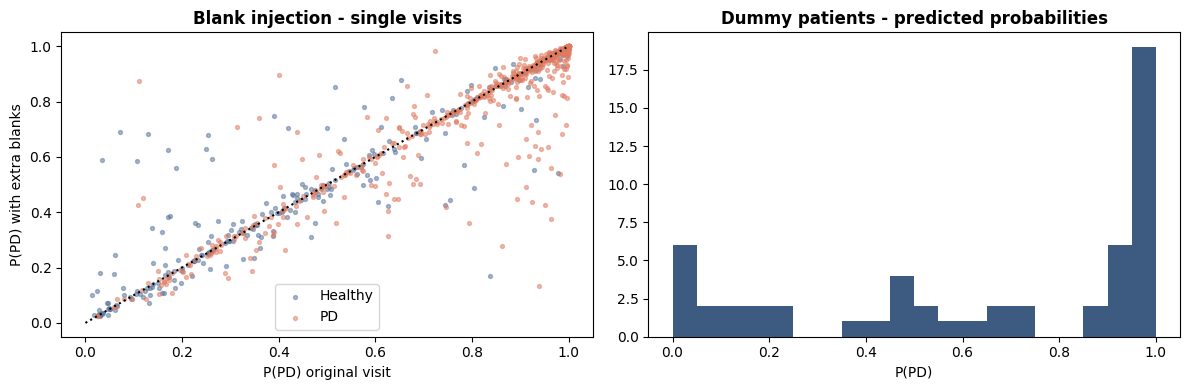

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
a, b = predict_new(te, "visit"), predict_new(te_blank, "visit")
for k, lab, col in [(2, "Healthy", "#577399"), (1, "PD", "#E07A5F")]:
    m = a["APPRDX"] == k
    ax[0].scatter(a.loc[m, "P_PD"], b.loc[m, "P_PD"], s=8, alpha=.5, c=col, label=lab)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("P(PD) original visit"); ax[0].set_ylabel("P(PD) with extra blanks")
ax[0].set_title("Blank injection - single visits", fontweight="bold"); ax[0].legend()
ax[1].hist(res["P_PD"].dropna(), bins=np.linspace(0, 1, 21), color="#3D5A80")
ax[1].set_xlabel("P(PD)"); ax[1].set_title("Dummy patients - predicted probabilities", fontweight="bold")
plt.tight_layout()
fig.savefig(os.path.join(rdir, "robustness_and_dummies.png"), bbox_inches="tight", dpi=150)
plt.show()